# Reto OT Consulting — Recursos Humanos
## Etapa 3: Acondicionamiento y corrección de los datos

**Equipo:** Franco Varela Villegas (A01199186) · Emilio Ogaz Galván (A01572029) · Angelica Velez Cantu (A01199359) · Melissa Anahid Esparza López (A01286887) · José Fernando Munguía Zertuche (A01199357)

---

### Cómo usar este cuaderno
1. Los 7 archivos del socio formador viven en `data/excel/` del repositorio; la celda de **Carga de archivos** los lee de ahí, sin subirlos a mano.
2. Si lo abres en Colab, clona el repositorio y apunta `DATOS` a la carpeta clonada.
3. `Entorno de ejecución > Ejecutar todo`.
4. Las tablas acondicionadas, el `log_correcciones`, el reporte de calidad y las gráficas quedan en `data/acondicionado/`, y al final se genera un `.zip` con todo.

El cuaderno implementa los 14 métodos de corrección (M1 a M14) documentados en el avance, registra cada cambio en `log_correcciones` y valida las reglas de negocio con SQL.


## 0. Instalación y configuración


In [1]:
# Dependencias: pandas, numpy, matplotlib, openpyxl y rapidfuzz (ver requirements.txt)
import os, re, io, glob, zipfile, unicodedata, sqlite3
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')          # el cuaderno corre sin pantalla; las gráficas se guardan en disco
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)

# Parámetros del análisis
FECHA_CORTE = pd.Timestamp('2026-11-20')   # cambia esta fecha para recalcular a otro mes
HORAS_MES   = 160                          # regla 10: costo por hora = sueldo integrado / 160
DATOS  = os.path.join('..', 'data', 'excel')          # los 7 archivos del repositorio
SALIDA = os.path.join('..', 'data', 'acondicionado')  # tablas, log y evidencias
os.makedirs(SALIDA, exist_ok=True)
print('Listo. Fecha de corte:', FECHA_CORTE.date())


Listo. Fecha de corte: 2026-11-20


## 1. Carga de archivos

Los 7 archivos fuente están en `data/excel/`. La celda siguiente los verifica y la de lectura los abre con su hoja
correspondiente. No hace falta subirlos: el cuaderno se ejecuta sobre el repositorio.

Dos libros traen una segunda hoja que es la que reconstruye la llave: **Proyectos** en el catálogo de clientes y
**Resguardos** en el inventario de activos.


In [2]:
# Los 7 archivos del socio formador viven en data/excel del repositorio.
# En Colab: clona el repo y ajusta DATOS a la carpeta clonada.
ARCHIVOS_FUENTE = {
    'colaboradores': 'Catalogo_Colaboradores.xlsx',
    'asignaciones':  'Asignaciones_Colaboradores.xlsx',
    'clientes':      'Catalogo_Clientes.xlsx',
    'activos':       'Catalogo_Activos.xlsx',
    'departamentos': 'Catalogo_Departamentos.xlsx',
    'habilidades':   'Catalogo_Habilidades.xlsx',
    'matriz':        'Matriz_Habilidades.xlsx',
}
faltantes = [f for f in ARCHIVOS_FUENTE.values() if not os.path.exists(os.path.join(DATOS, f))]
assert not faltantes, f'Faltan archivos en {os.path.abspath(DATOS)}: {faltantes}'
print(f'{len(ARCHIVOS_FUENTE)} archivos fuente encontrados en {DATOS}:')
for n, f in ARCHIVOS_FUENTE.items():
    print(f'  {n:14s} {f}')


7 archivos fuente encontrados en ../data/excel:
  colaboradores  Catalogo_Colaboradores.xlsx
  asignaciones   Asignaciones_Colaboradores.xlsx
  clientes       Catalogo_Clientes.xlsx
  activos        Catalogo_Activos.xlsx
  departamentos  Catalogo_Departamentos.xlsx
  habilidades    Catalogo_Habilidades.xlsx
  matriz         Matriz_Habilidades.xlsx


In [3]:
# OPCIÓN B — en Colab, clona el repositorio y apunta DATOS a la carpeta clonada:
# !git clone https://github.com/JoseFernandoMunguiaZertuche/otc-hr-data-audit.git
# DATOS = 'otc-hr-data-audit/data/excel'
print('Las rutas del cuaderno son relativas a la carpeta notebooks/.')


Las rutas del cuaderno son relativas a la carpeta notebooks/.


## 2. Lectura de los 7 archivos y perfilado inicial (calidad ANTES)


In [4]:
OCULTAR = 0  # (no se usa: la lectura es explícita por archivo y hoja)

def cargar(nombre, hoja=0):
    ruta = os.path.join(DATOS, ARCHIVOS_FUENTE[nombre])
    df = pd.read_excel(ruta, sheet_name=hoja)
    df.columns = [re.sub(r'\s+', '_', str(c).strip().lower()) for c in df.columns]
    etiqueta = hoja if isinstance(hoja, str) else 'principal'
    print(f'  {ARCHIVOS_FUENTE[nombre]:34s} {len(df):4d} filas  {len(df.columns):3d} columnas  (hoja: {etiqueta})')
    return df

print('Archivos cargados:')
raw = {
    'colaboradores': cargar('colaboradores'),
    'asignaciones':  cargar('asignaciones'),
    'clientes':      cargar('clientes', 'Clientes'),
    'activos':       cargar('activos', 'Activos'),
    'departamentos': cargar('departamentos'),
    'habilidades':   cargar('habilidades'),
    'matriz':        cargar('matriz'),
}
# Hojas complementarias del mismo libro: son las que traen la llave
raw['proyectos'] = cargar('clientes', 'Proyectos')
raw['resguardos'] = cargar('activos', 'Resguardos')


Archivos cargados:


  Catalogo_Colaboradores.xlsx         107 filas   39 columnas  (hoja: principal)
  Asignaciones_Colaboradores.xlsx      31 filas   13 columnas  (hoja: principal)


  Catalogo_Clientes.xlsx                8 filas   13 columnas  (hoja: Clientes)
  Catalogo_Activos.xlsx               123 filas   16 columnas  (hoja: Activos)
  Catalogo_Departamentos.xlsx           6 filas    7 columnas  (hoja: principal)
  Catalogo_Habilidades.xlsx            71 filas    6 columnas  (hoja: principal)


  Matriz_Habilidades.xlsx            1539 filas   10 columnas  (hoja: principal)
  Catalogo_Clientes.xlsx               12 filas   11 columnas  (hoja: Proyectos)
  Catalogo_Activos.xlsx                91 filas   12 columnas  (hoja: Resguardos)


In [5]:
CENTINELAS = {'','-','.','n/a','na','nd','null','none','pendiente','xxxx','xxx','por definir','indefinido','sin asignar'}
FECHAS_RELLENO = {'1990-01-01','1900-01-01','1970-01-01'}

def perfilar(dic, momento):
    filas = []
    for t, df in dic.items():
        for c in df.columns:
            cent = df[c].astype(str).str.strip().str.lower().isin(CENTINELAS)
            filas.append(dict(tabla=t, columna=c, momento=momento,
                completitud=round(df[c].notna().mean()*100, 1),
                completitud_real=round((df[c].notna() & ~cent).mean()*100, 1),
                centinelas=int(cent.sum()),
                valores_unicos=int(df[c].nunique(dropna=True))))
    return pd.DataFrame(filas)

calidad_antes = perfilar(raw, 'antes')
print('Columnas con menos de 50% de completitud:')
display(calidad_antes[calidad_antes.completitud < 50].sort_values('completitud').head(20))


Columnas con menos de 50% de completitud:


,tabla,columna,momento,completitud,completitud_real,centinelas,valores_unicos
37,colaboradores,notas,antes,0.0,0.0,0,0
60,clientes,contacto_tel,antes,0.0,0.0,0,0
61,clientes,telefono,antes,0.0,0.0,0,0
76,activos,fgarantia,antes,0.0,0.0,0,0
84,departamentos,responsable,antes,0.0,0.0,0,0
85,departamentos,centrocostos,antes,0.0,0.0,0,0
126,resguardos,notas,antes,1.1,1.1,0,1
79,activos,notas,antes,6.5,6.5,0,5
113,proyectos,email_cli,antes,8.3,8.3,0,1
114,proyectos,tel_cli,antes,8.3,8.3,0,1


**Lectura.** El perfilado confirma lo que documentamos en la exploración: las columnas críticas para el análisis (departamento, puesto, rol asignado, fecha de baja) están por debajo del 50% de completitud y hay cientos de valores centinela escritos como texto. Esto es lo que corrigen los métodos de las siguientes secciones.


## 3. Métodos M1 a M4 — texto, centinelas, catálogos y tipos

- **M1** normaliza el texto (espacios, acentos, formato título).
- **M2** convierte los valores centinela en nulo verdadero y levanta una bandera `falta_*`.
- **M3** homologa las variantes contra un catálogo (`MTY` y `Monterrey` quedan en un solo valor).
- **M4** convierte fechas, montos y los campos de documentación a su tipo correcto.


In [6]:
LOG = []
def log(tabla, columna, registro, original, corregido, metodo):
    LOG.append(dict(tabla=tabla, columna=columna, registro=registro, valor_original=str(original),
                    valor_corregido=str(corregido), metodo=metodo,
                    fecha=datetime.now().isoformat(timespec='seconds')))

# ---------- M1 ----------
def m1_texto(s, titulo=False, mayus=False):
    if pd.isna(s): return np.nan
    t = re.sub(r'\s+', ' ', unicodedata.normalize('NFC', str(s)).strip())
    if not t: return np.nan
    if titulo: t = t.title()
    if mayus:  t = t.upper()
    return t

# ---------- M2 ----------
def m2_centinela(v):
    if pd.isna(v): return np.nan
    t = str(v).strip().lower()
    return np.nan if (t in CENTINELAS or t in FECHAS_RELLENO) else v

def nulificar(df, cols, tabla, llave=None):
    for c in [c for c in cols if c in df.columns]:
        antes = df[c].copy()
        df[c] = df[c].map(m2_centinela)
        for i in df.index[antes.notna() & df[c].isna()]:
            log(tabla, c, df.at[i, llave] if llave and llave in df.columns else i, antes[i], None, 'M2')
        df['falta_'+c] = df[c].isna().astype(int)
    return df

# ---------- M3 ----------
CAT_CIUDAD = {'mty':'Monterrey','mty.':'Monterrey','monterrey n.l.':'Monterrey','monterrey, n.l.':'Monterrey',
              'gdl':'Guadalajara','cdmx':'Ciudad de México','mexico df':'Ciudad de México','saltillo coah':'Saltillo'}
CAT_MARCA  = {'hp':'HP','h.p.':'HP','hewlett packard':'HP','hewlett-packard':'HP','lenovo':'Lenovo','lenvo':'Lenovo',
              'dell':'Dell','dell inc':'Dell','apple':'Apple','mac':'Apple','macbook':'Apple','asus':'ASUS','acer':'Acer'}

def m3_catalogo(serie, mapa, tabla, columna):
    def f(v):
        if pd.isna(v): return np.nan
        nuevo = mapa.get(str(v).strip().lower(), m1_texto(v, titulo=True))
        if nuevo != v: log(tabla, columna, None, v, nuevo, 'M3')
        return nuevo
    return serie.map(f)

def catalogo_id(serie, nombre):
    vals = sorted(pd.Series(serie).dropna().unique())
    cat = pd.DataFrame({f'id_{nombre}': range(1, len(vals)+1), nombre: vals})
    return cat, pd.Series(serie).map(dict(zip(cat[nombre], cat[f'id_{nombre}'])))

# ---------- M4 ----------
def m4_fecha(s):  return pd.to_datetime(pd.Series(s).map(m2_centinela), errors='coerce')
def m4_monto(s):  return pd.to_numeric(pd.Series(s).astype(str).str.replace(r'[^0-9.\-]', '', regex=True).replace('', np.nan), errors='coerce')
def m4_documento(v):
    if pd.isna(v): return 0
    t = str(v).strip().lower()
    if t in ('si', 'sí', 's', '1', 'no aplica'): return 1   # NO APLICA cuenta como cumplido (regla 9)
    if t in ('no', 'n', '0', 'pendiente'): return 0
    return np.nan
print('Métodos M1 a M4 definidos')


Métodos M1 a M4 definidos


## 4. Método M5 — reconstrucción de llaves

Es la corrección que habilita todo lo demás: los activos se ligaban al colaborador **por nombre** y los proyectos no tenían código. Primero se intenta la unión exacta sobre el nombre normalizado y solo el remanente se resuelve con comparación difusa, dejando bandera en los que no se pudieron resolver.


In [7]:
from rapidfuzz import process, fuzz

def m5_llave(serie):
    def f(v):
        if pd.isna(v): return np.nan
        t = unicodedata.normalize('NFKD', str(v)).encode('ascii','ignore').decode()
        return re.sub(r'[^a-z0-9 ]','', t.lower()).strip()
    return pd.Series(serie).map(f)

def m5_resolver(df_hijo, col_nombre, df_padre, col_padre, id_padre, umbral=90):
    k_hijo, k_padre = m5_llave(df_hijo[col_nombre]), m5_llave(df_padre[col_padre])
    mapa = dict(zip(k_padre, df_padre[id_padre]))
    res = k_hijo.map(mapa)
    pend = res.isna() & k_hijo.notna()
    cand = list(mapa.keys())
    for i in df_hijo.index[pend]:
        m = process.extractOne(k_hijo[i], cand, scorer=fuzz.token_sort_ratio)
        if m and m[1] >= umbral:
            res[i] = mapa[m[0]]
            log('activo', col_nombre, i, df_hijo.at[i, col_nombre], m[0], 'M5-difuso')
    print(f'  resueltos {res.notna().sum()} de {k_hijo.notna().sum()}; sin identificar: {int((pend & res.isna()).sum())}')
    return res
print('Método M5 definido')


Método M5 definido


## 5. Colaboradores — M1, M2, M3, M4, M7, M8, M11 y atributos derivados

Aquí se aplica la decisión de fondo del acondicionamiento: **no se imputa**. Los sueldos en $0 se vuelven nulos con bandera en lugar de rellenarse con un promedio, y las 18 bajas sin fecha se reportan como faltantes, porque una fecha inventada distorsionaría directamente la rotación y la permanencia.


In [8]:
col = raw['colaboradores'].copy().rename(columns={
    'id': 'id_colaborador', 'nombre': 'nombre_completo', 'depto': 'departamento',
    'fechainc': 'fecha_incorporacion', 'fechabaja': 'fecha_baja',
    'fechanac': 'fecha_nacimiento', 'nomina': 'tipo_nomina'})

col['nombre_completo'] = col['nombre_completo'].map(lambda v: m1_texto(v, titulo=True))
col = nulificar(col, ['puesto', 'departamento', 'tipo_nomina', 'ciudad'], 'colaborador', 'id_colaborador')
if 'ciudad' in col:
    col['ciudad'] = m3_catalogo(col['ciudad'], CAT_CIUDAD, 'colaborador', 'ciudad')

for c in ['fecha_incorporacion', 'fecha_baja', 'fecha_nacimiento']:
    col[c] = m4_fecha(col[c])
col['estatus'] = col['estatus'].map(lambda v: m1_texto(v, titulo=True))

# M8 coherencia temporal
inc = (col['estatus'] == 'Activo') & col['fecha_baja'].notna()
for i in col.index[inc]:
    log('colaborador', 'fecha_baja', col.at[i, 'id_colaborador'], col.at[i, 'fecha_baja'], None, 'M8')
col.loc[inc, 'fecha_baja'] = pd.NaT
col['inconsistencia_estatus_fecha'] = inc.astype(int)
col['falta_fecha_baja'] = ((col['estatus'] == 'Baja') & col['fecha_baja'].isna()).astype(int)

# M11 sueldos: 0 -> nulo, nunca se imputa
col['sueldo_total_integrado'] = m4_monto(col['sueldo_total_integrado'])
cero = col['sueldo_total_integrado'] == 0
for i in col.index[cero]:
    log('colaborador', 'sueldo_total_integrado', col.at[i, 'id_colaborador'], 0, None, 'M11')
col.loc[cero, 'sueldo_total_integrado'] = np.nan
col['falta_sueldo'] = col['sueldo_total_integrado'].isna().astype(int)

# M7 familiares fuera de la plantilla: el puesto lo declara
col['es_plantilla'] = 1
fam = col['puesto'].astype(str).str.upper().str.contains('FAMILIAR')
for i in col.index[fam]:
    log('colaborador', 'es_plantilla', col.at[i, 'id_colaborador'], 1, 0, 'M7')
col.loc[fam, 'es_plantilla'] = 0

# M4 expediente: los documentos se capturan como SI / Pendiente / NO
docs = [c for c in col.columns if c.startswith(('doc', 'aviso', 'formato')) and c != 'doc_contrato']
for c in docs:
    col[c] = col[c].map(m4_documento)
col['pct_expediente'] = (col[docs].sum(axis=1) / len(docs) * 100).round(1)
col['expediente_completo'] = (col['pct_expediente'] == 100).astype(int)
# doc_contrato no es SI/NO: guarda la modalidad (Planta / Por Proyecto), y su ausencia es el dato faltante
col['tiene_contrato'] = col['doc_contrato'].notna().astype(int)

# Atributos derivados
fin = col['fecha_baja'].fillna(FECHA_CORTE)
col['antiguedad_meses'] = ((fin - col['fecha_incorporacion']).dt.days / 30.44).round(1)
col['edad']             = ((FECHA_CORTE - col['fecha_nacimiento']).dt.days / 365.25).floordiv(1)
col['baja_primer_anio'] = ((col['estatus'] == 'Baja') & (col['antiguedad_meses'] < 12)).astype(int)
col['costo_mensual']    = col['sueldo_total_integrado']
col['costo_hora']       = (col['costo_mensual'] / HORAS_MES).round(2)

cat_dep, col['id_departamento'] = catalogo_id(col['departamento'], 'departamento')
cat_pue, col['id_puesto']       = catalogo_id(col['puesto'], 'puesto')

print(f'{len(col)} colaboradores acondicionados | plantilla: {int(col.es_plantilla.sum())} | correcciones hasta aquí: {len(LOG)}')
display(col[['id_colaborador', 'nombre_completo', 'estatus', 'antiguedad_meses', 'costo_hora', 'pct_expediente']].head())


107 colaboradores acondicionados | plantilla: 105 | correcciones hasta aquí: 102


,id_colaborador,nombre_completo,estatus,antiguedad_meses,costo_hora,pct_expediente
0,OTC003,Abraham Perez Gil,Activo,125.3,373.32,69.2
1,OTC004,Adriana Perez Navarrete,Activo,51.6,371.23,84.6
2,OTC005,Alberto Perez Breton,Activo,130.3,419.18,53.8
3,OTC006,Alberto Antonio Perez Chee,Activo,128.8,409.46,53.8
4,OTC007,Alejandro Perez Morquecho,Baja,13.9,344.11,76.9


## 6. Clientes y proyectos — M5: el proyecto por fin tiene código propio


In [9]:
cli = raw['clientes'].copy().rename(columns={'codigo': 'codigo_cliente', 'nombre': 'cliente'})
for c in ['cliente', 'industria', 'ciudad', 'estado', 'pais', 'contacto_nom']:
    if c in cli:
        cli[c] = cli[c].map(lambda v: m1_texto(v, titulo=True))
cli = nulificar(cli, ['industria', 'ciudad', 'estado', 'contacto_nom'], 'cliente')
cat_cli, cli['id_cliente'] = catalogo_id(cli['cliente'], 'cliente')
cli['llave_cliente'] = m5_llave(cli['cliente'])
cat_cli['llave_cliente'] = m5_llave(cat_cli['cliente'])

pro = raw['proyectos'].copy()
for c in ['cliente', 'proyecto', 'pm_otc', 'resp_cli']:
    if c in pro:
        pro[c] = pro[c].map(lambda v: m1_texto(v, titulo=True))
pro = nulificar(pro, ['pm_otc', 'resp_cli'], 'proyecto')
pro['id_proyecto'] = range(1, len(pro) + 1)
pro['llave_cliente'] = m5_llave(pro['cliente'])
pro['llave_proyecto'] = m5_llave(pro['cliente']) + '|' + m5_llave(pro['proyecto'])
pro = pro.merge(cat_cli[['llave_cliente', 'id_cliente']], on='llave_cliente', how='left')
pro['fecha_inicio'] = m4_fecha(pro['inicio'])
pro['fecha_fin'] = m4_fecha(pro['fin'])

print(f'{cli.id_cliente.nunique()} clientes y {len(pro)} proyectos, ahora con llave propia')
display(pro[['id_cliente', 'cliente', 'id_proyecto', 'proyecto', 'estatus']].head())


8 clientes y 12 proyectos, ahora con llave propia


,id_cliente,cliente,id_proyecto,proyecto,estatus
0,5,Metalsa,1,Ams Manufactura,En Curso
1,5,Metalsa,2,Soporte Ams Manufacta,En Curso
2,5,Metalsa,3,Asignación Indefinida,Por Iniciar
3,4,Grupo Daltile,4,Marazzi,En Curso
4,4,Grupo Daltile,5,Asignación Ebs Temporal (3 Meses),Por Iniciar


## 7. Asignaciones — M2, M9 y M10

El caso de la persona en dos proyectos a la vez **no es un error**: la regla 11 lo permite mientras la dedicación sume 100% o menos. Lo que se hace es medir la dedicación y marcar al sobreasignado. El M10 cierra las asignaciones del personal dado de baja, que es lo que estaba inflando la utilización.


In [10]:
asg = raw['asignaciones'].copy()
asg = nulificar(asg, ['rol', 'tipo', 'estatus'], 'asignacion')
asg['fecha_inicio'] = m4_fecha(asg['inicio'])
asg['fecha_fin'] = m4_fecha(asg['fin'])
asg['falta_fecha_inicio'] = asg['fecha_inicio'].isna().astype(int)
asg['llave_proyecto'] = m5_llave(asg['cliente']) + '|' + m5_llave(asg['proyecto'])
asg = asg.merge(pro[['llave_proyecto', 'id_proyecto', 'id_cliente']], on='llave_proyecto', how='left')
# respaldo por código de cliente cuando el nombre del proyecto no está en el catálogo
sin_proy = asg['id_proyecto'].isna()
if sin_proy.any():
    asg.loc[sin_proy, 'id_cliente'] = asg.loc[sin_proy, 'codigo_cliente'].map(cli.set_index('codigo_cliente')['id_cliente'])
asg['id_asignacion'] = range(1, len(asg) + 1)
asg = asg.rename(columns={'rol': 'rol_asignado', 'tipo': 'tipo_de_asignacion'})

# M9 dedicación: el sistema no captura el porcentaje, así que cada asignación se toma al 100% y se marca estimada
n = asg.groupby('id_colaborador')['id_asignacion'].transform('count')
asg['pct_dedicacion'] = 100.0
asg['pct_dedicacion_estimado'] = (n > 1).astype(int)

# M10 cierre por baja
asg = asg.merge(col[['id_colaborador', 'fecha_baja', 'estatus']].rename(columns={'estatus': 'estatus_colab'}),
                on='id_colaborador', how='left')
cerrar = asg['fecha_baja'].notna() & (asg['fecha_fin'].isna() | (asg['fecha_fin'] > asg['fecha_baja']))
for i in asg.index[cerrar]:
    log('asignacion', 'fecha_fin', asg.at[i, 'id_asignacion'], asg.at[i, 'fecha_fin'], asg.at[i, 'fecha_baja'], 'M10')
asg.loc[cerrar, 'fecha_fin'] = asg.loc[cerrar, 'fecha_baja']

asg['vigente'] = ((asg['fecha_inicio'].fillna(FECHA_CORTE) <= FECHA_CORTE) &
                  (asg['fecha_fin'].isna() | (asg['fecha_fin'] >= FECHA_CORTE))).astype(int)
asg['dias_para_fin'] = (asg['fecha_fin'] - FECHA_CORTE).dt.days

vig = asg[asg['vigente'] == 1]
col['tiene_asignacion_vigente'] = col['id_colaborador'].isin(vig['id_colaborador']).astype(int)
col['dedicacion_total_pct'] = col['id_colaborador'].map(vig.groupby('id_colaborador')['pct_dedicacion'].sum())
col['sobreasignado'] = (col['dedicacion_total_pct'] > 100).astype(int)
ult = asg.groupby('id_colaborador')['fecha_fin'].max()
base = col['id_colaborador'].map(ult).fillna(col['fecha_incorporacion'])
col['dias_en_banca'] = np.where(col['tiene_asignacion_vigente'] == 0, (FECHA_CORTE - base).dt.days, np.nan)

print(f'{int(cerrar.sum())} asignaciones cerradas por baja | vigentes: {int(asg.vigente.sum())} | sobreasignados: {int(col.sobreasignado.sum())}')


0 asignaciones cerradas por baja | vigentes: 31 | sobreasignados: 1


## 8. Activos — M3, M5 y M11: el equipo deja de ligarse por nombre

La liga activo → colaborador no viene en el inventario: viene en la hoja **Resguardos**, que sí trae `id_colaborador`.
Se usa esa llave y solo se marca como `sin_asignar` el equipo que no tiene resguardo. La marca se homologa contra
catálogo y el costo en \$0 se vuelve nulo con bandera, porque un cero se suma y distorsiona la inversión en equipo.


In [11]:
act = raw['activos'].copy()
act['marca'] = act['marca'].map(lambda v: m1_texto(v, titulo=True))
act['marca'] = m3_catalogo(act['marca'], CAT_MARCA, 'activo', 'marca')

# M5: la llave está en la hoja de resguardos
res = raw['resguardos'].copy().rename(columns={'codigo_activo': 'codigo'})
res['fecha_ini'] = m4_fecha(res['f_ini'])
res['fecha_fin'] = m4_fecha(res['f_fin'])
res = res.drop_duplicates('codigo')
act = act.merge(res[['codigo', 'id_colaborador', 'colaborador', 'estatus_colaborador', 'fecha_ini', 'fecha_fin']],
                on='codigo', how='left')
act['liga_resguardo'] = act['id_colaborador'].notna().astype(int)
act['sin_asignar'] = act['id_colaborador'].isna().astype(int)

act['costo'] = m4_monto(act['costo'])
cero = act['costo'] == 0
for i in act.index[cero]:
    log('activo', 'costo', i, 0, None, 'M11')
act.loc[cero, 'costo'] = np.nan
act['costo_desconocido'] = act['costo'].isna().astype(int)

# la fecha de fin del resguardo es la que dice si el equipo ya volvió
act['pendiente_recuperar'] = ((act['estatus_colaborador'] == 'Baja') & act['fecha_fin'].isna()).astype(int)
col['inversion_equipo_col'] = col['id_colaborador'].map(
    act[act.pendiente_recuperar == 0].groupby('id_colaborador')['costo'].sum())

print(f'Activos ligados por resguardo: {int(act.liga_resguardo.sum())} de {len(act)} | sin asignar: {int(act.sin_asignar.sum())}')
print(f'Equipos pendientes de recuperar: {int(act.pendiente_recuperar.sum())} | marcas distintas tras homologar: {act.marca.nunique()}')


Activos ligados por resguardo: 91 de 123 | sin asignar: 32
Equipos pendientes de recuperar: 9 | marcas distintas tras homologar: 5


## 9. Habilidades y matriz — M6 y M12

La matriz de este archivo ya viene en formato largo, con una fila por colaborador y habilidad, así que el M12 la
usa tal cual y solo convierte el nivel a la escala ordinal 1 a 4. Si la exportación llegara en formato ancho, el mismo
código la pasa a largo. Diez filas venían solo con `uid`, sin `id_colaborador`: se reconstruyen con el M5.


In [12]:
hab = raw['habilidades'].copy().rename(columns={'codigo': 'cod_habilidad'})
for c in ['descripcion', 'tecnologia', 'tipo']:
    if c in hab:
        hab[c] = hab[c].map(lambda v: m1_texto(v, titulo=True))
dup = hab.duplicated('descripcion', keep=False)
hab['descripcion_repetida'] = dup.astype(int)
hab['descripcion_unica'] = np.where(dup, hab['descripcion'] + ' (' + hab['tecnologia'] + ')', hab['descripcion'])
for i in hab.index[dup]:
    log('habilidad', 'descripcion', i, hab.at[i, 'descripcion'], hab.at[i, 'descripcion_unica'], 'M6')

NIVEL = {'basico': 1, 'básico': 1, 'intermedio': 2, 'avanzado': 3, 'experto': 4}
mat = raw['matriz'].copy()

# M5 dentro de la matriz: el id venía vacío en 10 filas
falta_id = mat['id_colaborador'].isna() & mat['uid_colaborador'].notna()
if falta_id.any():
    mat.loc[falta_id, 'id_colaborador'] = mat.loc[falta_id, 'uid_colaborador'].map(col.set_index('uid')['id_colaborador'])
    for i in mat.index[falta_id]:
        log('matriz', 'id_colaborador', i, None, mat.at[i, 'id_colaborador'], 'M5')
mat['sin_colaborador'] = mat['id_colaborador'].isna().astype(int)

if {'codigo_habilidad', 'nivel'}.issubset(mat.columns):
    mlong = mat.rename(columns={'codigo_habilidad': 'cod_habilidad'})[['id_colaborador', 'cod_habilidad', 'nivel']].copy()
    mlong['nivel_txt'] = mlong['nivel']
    mlong = mlong.drop(columns='nivel')
    print('La matriz ya venía en formato largo: no hizo falta unpivot (M12).')
else:
    idm = [c for c in mat.columns if 'colaborador' in c or c == 'id'][0]
    mlong = mat.melt(id_vars=[idm], var_name='cod_habilidad', value_name='nivel_txt').rename(columns={idm: 'id_colaborador'})
    log('matriz', 'formato', 'matriz', 'ancho', 'largo', 'M12')
    print(f'M12 aplicado: {mat.shape[0]} × {mat.shape[1]} en formato ancho -> {len(mlong)} filas')

mlong['nivel_num'] = mlong['nivel_txt'].map(lambda v: NIVEL.get(str(v).strip().lower(), np.nan))
mlong = mlong[mlong['nivel_txt'].notna()]

expertos = (mlong[mlong.nivel_num >= 3].groupby('cod_habilidad')['id_colaborador'].nunique()
            .rename('expertos_por_habilidad').reset_index())
expertos['riesgo_persona_clave'] = (expertos.expertos_por_habilidad <= 1).astype(int)
print(f'Matriz en formato largo: {len(mlong)} evaluaciones ({int(mlong.id_colaborador.notna().sum())} con colaborador '
      f'identificado, {int(mlong.id_colaborador.isna().sum())} sin identificar) | {mlong.id_colaborador.nunique()} colaboradores | '
      f'{mlong.cod_habilidad.nunique()} habilidades | riesgo de persona clave: {int(expertos.riesgo_persona_clave.sum())}')
display(mlong.sort_values('id_colaborador', na_position='last').head())


La matriz ya venía en formato largo: no hizo falta unpivot (M12).
Matriz en formato largo: 1539 evaluaciones (1529 con colaborador identificado, 10 sin identificar) | 54 colaboradores | 71 habilidades | riesgo de persona clave: 7


,id_colaborador,cod_habilidad,nivel_txt,nivel_num
10,OTC003,H0052,Experto,4
38,OTC003,H0011,Intermedio,2
39,OTC003,H0026,Básico,1
40,OTC003,H0003,Básico,1
41,OTC003,H0008,Intermedio,2


## 10. Método M14 — tablas de extensión

Lo que no existe en la fuente no se puede corregir: hay que crearlo. Estas estructuras quedan con su llave y su dominio definidos, y los indicadores que dependen de ellas ya están programados; se activan en cuanto el socio formador capture la información.


In [13]:
ext = {
 'baja':            pd.DataFrame(columns=['id_baja','id_colaborador','fecha_baja','tipo_baja','causa_baja','es_voluntaria']),
 'registro_horas':  pd.DataFrame(columns=['id_registro','id_asignacion','semana','horas','facturable']),
 'tarifa_proyecto': pd.DataFrame(columns=['id_proyecto','id_puesto','tarifa_hora','moneda','vigencia_desde']),
 'certificacion':   pd.DataFrame(columns=['id_certificacion','id_colaborador','cod_habilidad','fecha_obtencion','fecha_vencimiento']),
}
for k, v in ext.items(): print(f'  {k:18s} {list(v.columns)}')


  baja               ['id_baja', 'id_colaborador', 'fecha_baja', 'tipo_baja', 'causa_baja', 'es_voluntaria']
  registro_horas     ['id_registro', 'id_asignacion', 'semana', 'horas', 'facturable']
  tarifa_proyecto    ['id_proyecto', 'id_puesto', 'tarifa_hora', 'moneda', 'vigencia_desde']
  certificacion      ['id_certificacion', 'id_colaborador', 'cod_habilidad', 'fecha_obtencion', 'fecha_vencimiento']


## 11. Carga a SQLite y reporte de calidad DESPUÉS


In [14]:
dep = raw['departamentos'].copy()
dep['nombre'] = dep['nombre'].map(lambda v: m1_texto(v, titulo=True))
dep['centro_costos'] = dep['centrocostos']
dep['responsable'] = dep['responsable'].map(lambda v: m1_texto(v, titulo=True))

tablas = {
    'colaborador_acondicionado': col,
    'asignacion_acondicionada':  asg,
    'cliente_acondicionado':     cli,
    'proyecto_acondicionado':    pro,
    'activo_acondicionado':      act,
    'departamento_acondicionado': dep,
    'habilidad_acondicionada':   hab,
    'matriz_habilidad_long':     mlong,
    'kpi_habilidad':             expertos,
    'cat_departamento':          cat_dep,
    'cat_puesto':                cat_pue,
    'cat_cliente':               cat_cli,
    **ext,
}

# el perfilado de después vive en la tabla acondicionada: se regresa al nombre de la fuente para comparar
MAPA_TABLA = {'colaborador_acondicionado': 'colaboradores', 'asignacion_acondicionada': 'asignaciones',
              'cliente_acondicionado': 'clientes', 'proyecto_acondicionado': 'proyectos',
              'activo_acondicionado': 'activos', 'departamento_acondicionado': 'departamentos',
              'habilidad_acondicionada': 'habilidades', 'matriz_habilidad_long': 'matriz'}
despues = perfilar({k: v for k, v in tablas.items() if len(v)}, 'despues')
despues['tabla'] = despues['tabla'].replace(MAPA_TABLA)
calidad = pd.concat([calidad_antes, despues], ignore_index=True)
log_df = pd.DataFrame(LOG)
tablas['calidad_datos'] = calidad
tablas['log_correcciones'] = log_df

con = sqlite3.connect(os.path.join(SALIDA, 'otc_rh.db'))
for nombre, df in tablas.items():
    df.to_sql(nombre, con, if_exists='replace', index=False)
    df.to_csv(os.path.join(SALIDA, f'{nombre}.csv'), index=False)
print(f'{len(tablas)} tablas cargadas en otc_rh.db | {len(log_df)} correcciones registradas')

# Completitud aparente contra real: lo que el centinela tapaba (M2)
comp = (calidad_antes[calidad_antes.centinelas > 0]
        .assign(brecha=lambda d: d.completitud - d.completitud_real)
        .sort_values('brecha', ascending=False)
        .head(15)[['tabla', 'columna', 'completitud', 'completitud_real', 'centinelas']])
comp.columns = ['tabla', 'columna', 'completitud_aparente', 'completitud_real', 'centinelas']
display(comp)


18 tablas cargadas en otc_rh.db | 265 correcciones registradas


,tabla,columna,completitud_aparente,completitud_real,centinelas
22,colaboradores,med_condiciones,97.2,0.0,104
47,asignaciones,rol,100.0,6.5,29
35,colaboradores,aviso_infonavit,100.0,11.2,95
36,colaboradores,aviso_manutencion,98.1,9.3,95
29,colaboradores,doc_foto,100.0,32.7,72
98,matriz,puesto,99.4,52.0,729
43,asignaciones,puesto_colaborador,100.0,54.8,14
2,colaboradores,puesto,100.0,55.1,48
27,colaboradores,doc_csf,100.0,63.6,39
25,colaboradores,doc_compdom,100.0,63.6,39


## 12. Validación de las reglas de negocio con SQL

Esta es la evidencia de que el acondicionamiento funcionó: todos los conteos de la primera parte deben quedar en **cero**.


In [15]:
VALIDACIONES = {
 'Activos con fecha de baja (regla 6)': "SELECT COUNT(*) FROM colaborador_acondicionado WHERE estatus='Activo' AND fecha_baja IS NOT NULL",
 'Fecha de baja anterior al ingreso (regla 7)': 'SELECT COUNT(*) FROM colaborador_acondicionado WHERE fecha_baja < fecha_incorporacion',
 'Asignaciones vigentes de personal dado de baja (regla 13)': "SELECT COUNT(*) FROM asignacion_acondicionada WHERE vigente=1 AND estatus_colab='Baja'",
 'Sueldos capturados en cero (regla 5)': 'SELECT COUNT(*) FROM colaborador_acondicionado WHERE sueldo_total_integrado=0',
 'Costos de activo en cero (regla 17)': 'SELECT COUNT(*) FROM activo_acondicionado WHERE costo=0',
}
PENDIENTES = {
 'Bajas sin fecha de baja (captura pendiente)': "SELECT COUNT(*) FROM colaborador_acondicionado WHERE estatus='Baja' AND fecha_baja IS NULL",
 'Colaboradores sobreasignados (regla 11)': 'SELECT COUNT(*) FROM colaborador_acondicionado WHERE sobreasignado=1',
 'Activos sin dueño identificado (regla 1)': 'SELECT COUNT(*) FROM activo_acondicionado WHERE sin_asignar=1',
 'Equipo pendiente de recuperar (regla 18)': 'SELECT COUNT(*) FROM activo_acondicionado WHERE pendiente_recuperar=1',
}
print('REGLAS QUE DEBEN QUEDAR EN CERO')
for d, q in VALIDACIONES.items():
    print(f'  {"OK " if con.execute(q).fetchone()[0] == 0 else "REVISAR"}  {d}: {con.execute(q).fetchone()[0]}')
print()
print('HALLAZGOS QUE SE REPORTAN A RH (no son error del proceso)')
for d, q in PENDIENTES.items():
    print(f'  {d}: {con.execute(q).fetchone()[0]}')


REGLAS QUE DEBEN QUEDAR EN CERO
  OK   Activos con fecha de baja (regla 6): 0
  OK   Fecha de baja anterior al ingreso (regla 7): 0
  OK   Asignaciones vigentes de personal dado de baja (regla 13): 0
  OK   Sueldos capturados en cero (regla 5): 0
  OK   Costos de activo en cero (regla 17): 0

HALLAZGOS QUE SE REPORTAN A RH (no son error del proceso)
  Bajas sin fecha de baja (captura pendiente): 18
  Colaboradores sobreasignados (regla 11): 1
  Activos sin dueño identificado (regla 1): 32
  Equipo pendiente de recuperar (regla 18): 9


## 13. Indicadores sobre los datos acondicionados


In [16]:
INDICADORES = {
 'Plantilla activa': "SELECT COUNT(*) FROM colaborador_acondicionado WHERE estatus='Activo' AND es_plantilla=1",
 'Consultores en banca': "SELECT COUNT(*) FROM colaborador_acondicionado WHERE estatus='Activo' AND es_plantilla=1 AND tiene_asignacion_vigente=0",
 'Costo mensual de la banca': "SELECT ROUND(SUM(costo_mensual),2) FROM colaborador_acondicionado WHERE estatus='Activo' AND tiene_asignacion_vigente=0",
 'Bajas en el primer año': 'SELECT COUNT(*) FROM colaborador_acondicionado WHERE baja_primer_anio=1',
 'Permanencia promedio al salir (meses)': "SELECT ROUND(AVG(antiguedad_meses),1) FROM colaborador_acondicionado WHERE estatus='Baja'",
 'Expedientes completos': 'SELECT COUNT(*) FROM colaborador_acondicionado WHERE expediente_completo=1',
 'Sin contrato firmado': 'SELECT COUNT(*) FROM colaborador_acondicionado WHERE tiene_contrato IS NOT 1',
 'Valor del equipo no recuperado': 'SELECT ROUND(SUM(costo),2) FROM activo_acondicionado WHERE pendiente_recuperar=1',
 'Habilidades con riesgo de persona clave': 'SELECT COUNT(*) FROM kpi_habilidad WHERE riesgo_persona_clave=1',
}
for d,q in INDICADORES.items(): print(f'  {d}: {con.execute(q).fetchone()[0]}')


  Plantilla activa: 73
  Consultores en banca: 43
  Costo mensual de la banca: 1994153.78
  Bajas en el primer año: 7
  Permanencia promedio al salir (meses): 25.2
  Expedientes completos: 0
  Sin contrato firmado: 92
  Valor del equipo no recuperado: 40693.0
  Habilidades con riesgo de persona clave: 7


## 14. Gráficas del prototipo


Gráfica guardada en ../data/acondicionado/graficas_prototipo.png


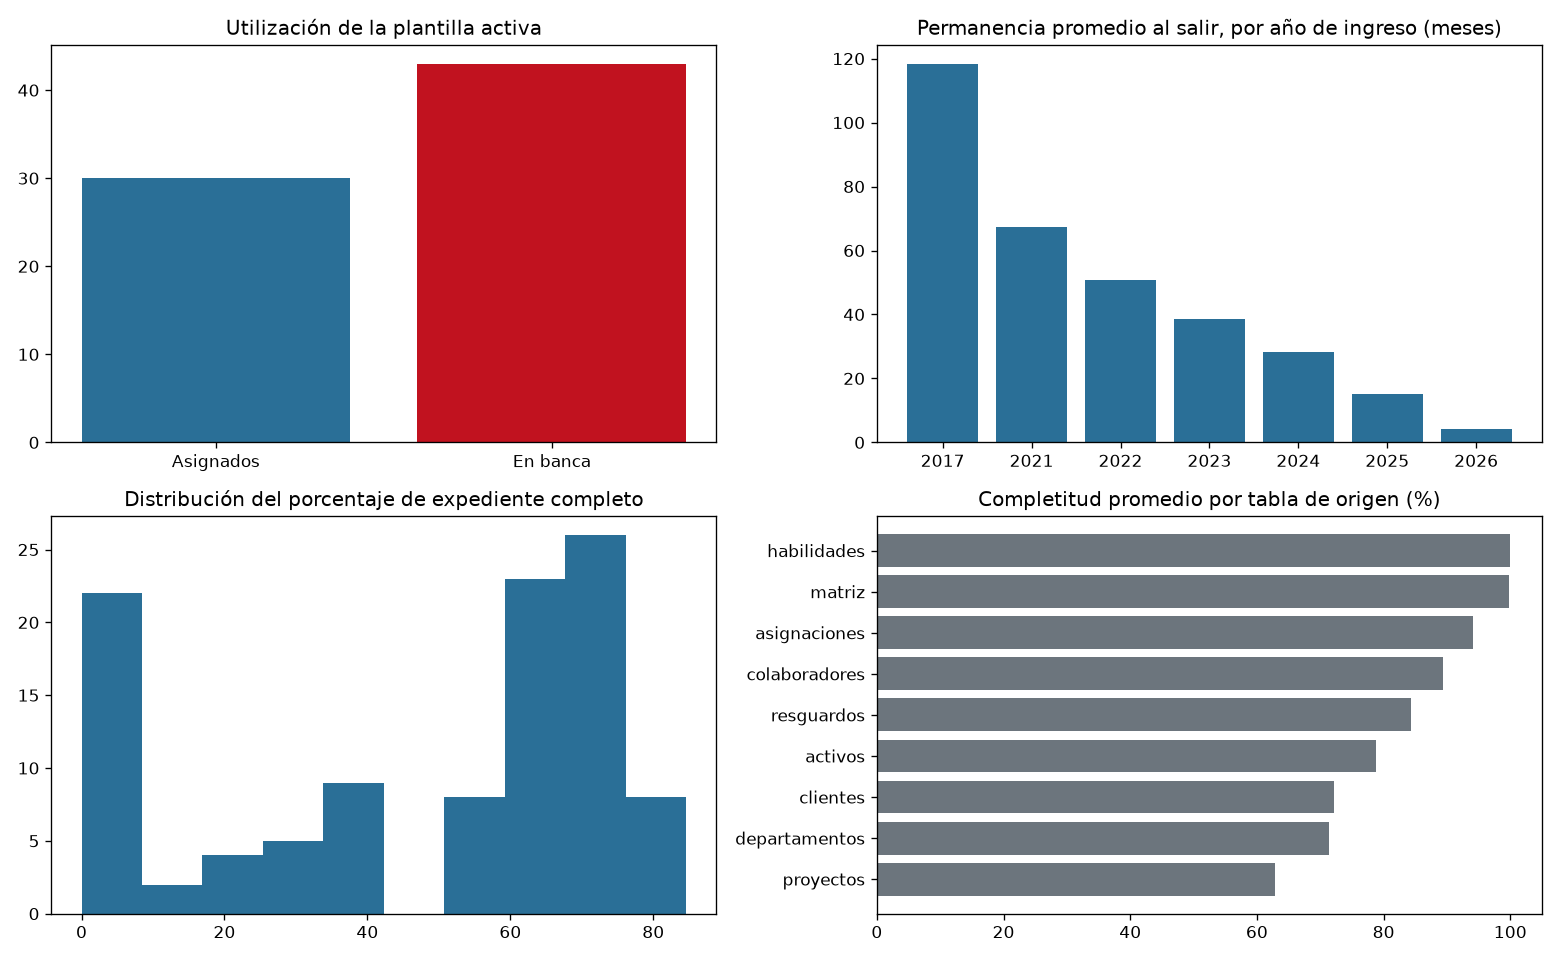

In [17]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))

act_pl = col[(col.estatus == 'Activo') & (col.es_plantilla == 1)]
ax[0, 0].bar(['Asignados', 'En banca'],
             [int(act_pl.tiene_asignacion_vigente.sum()), int((act_pl.tiene_asignacion_vigente == 0).sum())],
             color=['#2a6f97', '#c1121f'])
ax[0, 0].set_title('Utilización de la plantilla activa')

bajas = col[(col.estatus == 'Baja') & col.fecha_incorporacion.notna()]
coh = bajas.groupby(bajas.fecha_incorporacion.dt.year)['antiguedad_meses'].mean()
ax[0, 1].bar(coh.index.astype(str), coh.values, color='#2a6f97')
ax[0, 1].set_title('Permanencia promedio al salir, por año de ingreso (meses)')

ax[1, 0].hist(col['pct_expediente'].dropna(), bins=10, color='#2a6f97')
ax[1, 0].set_title('Distribución del porcentaje de expediente completo')

comp_t = calidad[calidad.momento == 'antes'].groupby('tabla')['completitud'].mean().sort_values()
ax[1, 1].barh(comp_t.index, comp_t.values, color='#6c757d')
ax[1, 1].set_title('Completitud promedio por tabla de origen (%)')

plt.tight_layout()
plt.savefig(os.path.join(SALIDA, 'graficas_prototipo.png'), dpi=120)
print('Gráfica guardada en', os.path.join(SALIDA, 'graficas_prototipo.png'))
from IPython.display import Image, display
display(Image(filename=os.path.join(SALIDA, 'graficas_prototipo.png')))


## 15. Descargar el resultado

Genera un `.zip` con la base, los CSV de las tablas acondicionadas, el log de correcciones y el reporte de calidad.
Ese archivo es el que se sube al repositorio y a Drive como evidencia.


In [18]:
con.close()
zip_path = os.path.join(SALIDA, 'OTC_RH_acondicionamiento.zip')
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
    for f in glob.glob(os.path.join(SALIDA, '*')):
        if not f.endswith('.zip'):
            z.write(f, os.path.join('salida', os.path.basename(f)))
print('Contenido del zip:')
for n in zipfile.ZipFile(zip_path).namelist():
    print('  ', n)


Contenido del zip:
   salida/certificacion.csv
   salida/cat_cliente.csv
   salida/otc_rh.db
   salida/baja.csv
   salida/graficas_prototipo.png
   salida/registro_horas.csv
   salida/matriz_habilidad_long.csv
   salida/colaborador_acondicionado.csv
   salida/calidad_datos.csv
   salida/departamento_acondicionado.csv
   salida/cat_puesto.csv
   salida/proyecto_acondicionado.csv
   salida/log_correcciones.csv
   salida/habilidad_acondicionada.csv
   salida/kpi_habilidad.csv
   salida/tarifa_proyecto.csv
   salida/activo_acondicionado.csv
   salida/cliente_acondicionado.csv
   salida/cat_departamento.csv
   salida/asignacion_acondicionada.csv
